# Bengaluru House Prices — Exploratory Data Analysis

This notebook explores the Kaggle *Bengaluru House Price Data* and motivates the cleaning rules in `ml/preprocess.py`. All cleaning logic is **imported from `ml/`** — nothing here is notebook-only, so the notebook and the training pipeline can never drift apart.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from ml import config
from ml import evaluate  # noqa: F401  (applies the shared plot style)
from ml.preprocess import load_raw, run_pipeline, add_bhk, convert_sqft, drop_missing, drop_unused_columns

BLUE, ORANGE, GREY = evaluate.SERIES_BLUE, evaluate.SERIES_ORANGE, evaluate.TEXT_SECONDARY
%matplotlib inline

## 1. Raw data at a glance

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
raw.isna().sum().to_frame('missing').T

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
missing,0,0,1,16,5502,0,73,609,0


**Takeaways:** `society` is missing for ~40% of rows and `balcony` for ~5% — we drop both, along with `area_type` and `availability`, to keep the model small and explainable. Only a handful of rows lack `location`, `size` or `bath`, so dropping them costs little.

## 2. Run the cleaning pipeline

The same function `ml.train` calls, with a row count for every step.

In [4]:
clean, log = run_pipeline(raw, verbose=False)
pd.DataFrame(log)

,step,before,after,dropped
0,Drop unused columns,13320,13320,0
1,Drop rows missing location/size/bath,13320,13246,74
2,Parse size -> bhk,13246,13246,0
3,Convert total_sqft to sq ft,13246,13246,0
4,Clean + group rare locations,13246,13246,0
5,Add price_per_sqft,13246,13246,0
6,Remove sqft/bhk < 300,13246,12498,748
7,Remove per-location pps outliers (mean +/- 1 std),12498,10315,2183
8,Remove BHK price-inversion outliers,10315,7393,2922
9,Remove bath > bhk + 2,7393,7389,4


In [5]:
# A lightly-parsed (but not outlier-filtered) frame for 'before' comparisons
parsed = convert_sqft(add_bhk(drop_missing(drop_unused_columns(raw))))
parsed['price_per_sqft'] = parsed['price'] * 1e5 / parsed['total_sqft']
clean = clean.assign(price_per_sqft=clean['price'] * 1e5 / clean['total_sqft'])
print(f'raw rows: {len(raw)}, parsed: {len(parsed)}, clean: {len(clean)}')

raw rows: 13320, parsed: 13246, clean: 7382


## 3. Price distribution — raw vs log

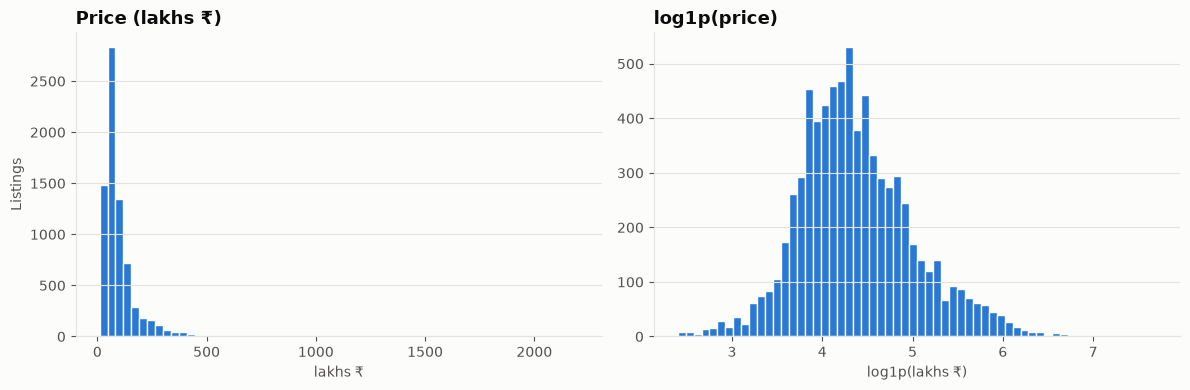

skew raw: 6.32   skew log: 0.51


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean['price'], bins=60, color=BLUE, edgecolor='#fcfcfb')
axes[0].set_title('Price (lakhs ₹)'); axes[0].set_xlabel('lakhs ₹'); axes[0].set_ylabel('Listings')
axes[1].hist(np.log1p(clean['price']), bins=60, color=BLUE, edgecolor='#fcfcfb')
axes[1].set_title('log1p(price)'); axes[1].set_xlabel('log1p(lakhs ₹)')
for ax in axes: ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(f"skew raw: {clean['price'].skew():.2f}   skew log: {np.log1p(clean['price']).skew():.2f}")

**Takeaway:** prices are heavily right-skewed (a long tail of multi-crore homes). The log transform makes the target close to symmetric, which is why every model is wrapped in `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`. It also means errors are effectively penalised in *relative* terms, which suits prices.

## 4. Price per sqft across the 15 most-listed locations

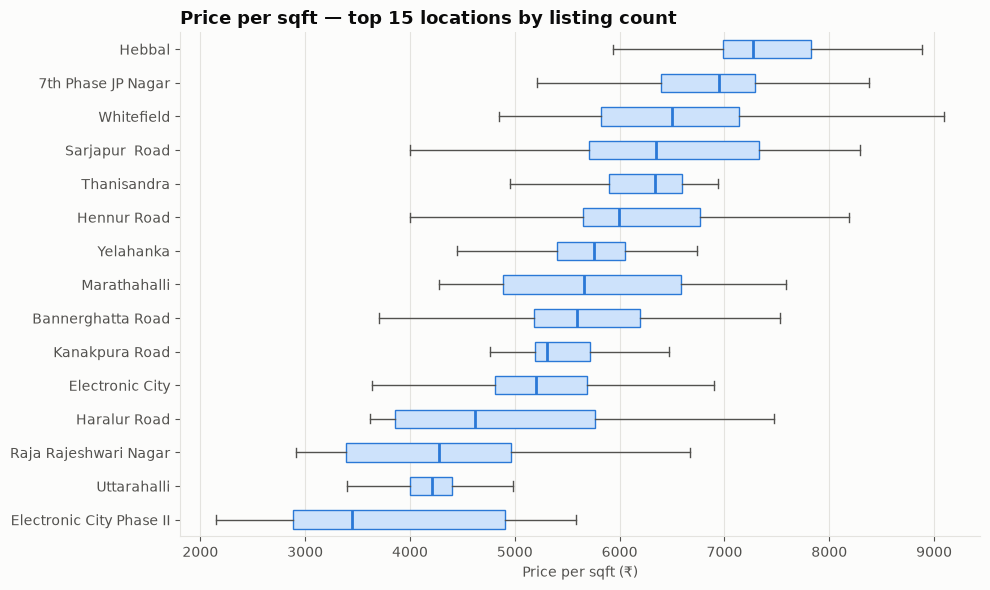

In [7]:
top15 = clean.loc[clean['location'] != config.OTHER_LOCATION, 'location'].value_counts().head(15).index
subset = clean[clean['location'].isin(top15)]
order = subset.groupby('location')['price_per_sqft'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([subset.loc[subset['location'] == loc, 'price_per_sqft'] for loc in order], orientation='horizontal',
           tick_labels=list(order), widths=0.55, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor='#cde2fb', edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=GREY), capprops=dict(color=GREY))
ax.grid(axis='y', visible=False)
ax.set_xlabel('Price per sqft (₹)'); ax.set_title('Price per sqft — top 15 locations by listing count')
plt.tight_layout(); plt.show()

**Takeaway:** location shifts the price per sqft by more than 2× between the cheapest and dearest of the busiest localities, so location is a must-have feature. It is one-hot encoded inside the pipeline; localities with ≤10 listings are pooled into `other` so each category has enough data.

## 5. Area vs price

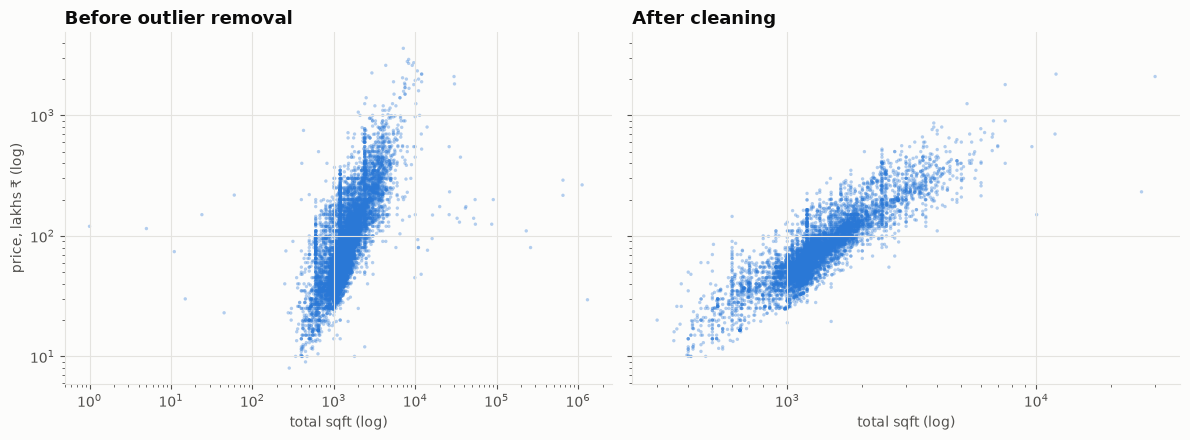

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, frame, title in [(axes[0], parsed, 'Before outlier removal'), (axes[1], clean, 'After cleaning')]:
    ax.scatter(frame['total_sqft'], frame['price'], s=6, alpha=0.35, color=BLUE, edgecolors='none')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(title)
    ax.set_xlabel('total sqft (log)')
axes[0].set_ylabel('price, lakhs ₹ (log)')
plt.tight_layout(); plt.show()

**Takeaway:** on log–log axes price rises roughly linearly with area. Before cleaning there are obvious data errors (tiny areas with many bedrooms, a 15-acre "3 BHK"); the outlier rules remove most of that noise. The log–log shape is also why linear models get `log1p(total_sqft)`.

## 6. BHK counts

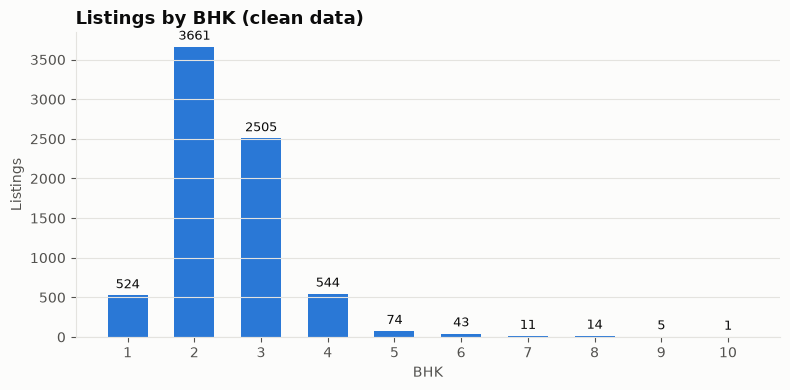

In [9]:
counts = clean['bhk'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, padding=3, color='#0b0b0b', fontsize=9)
ax.grid(axis='x', visible=False)
ax.set_xlabel('BHK'); ax.set_ylabel('Listings'); ax.set_title('Listings by BHK (clean data)')
plt.tight_layout(); plt.show()

**Takeaway:** 2 and 3 BHK dominate. Very large homes (6+ BHK) are rare, so predictions for them rest on little data and should be treated with extra caution.

## 7. Correlation heatmap

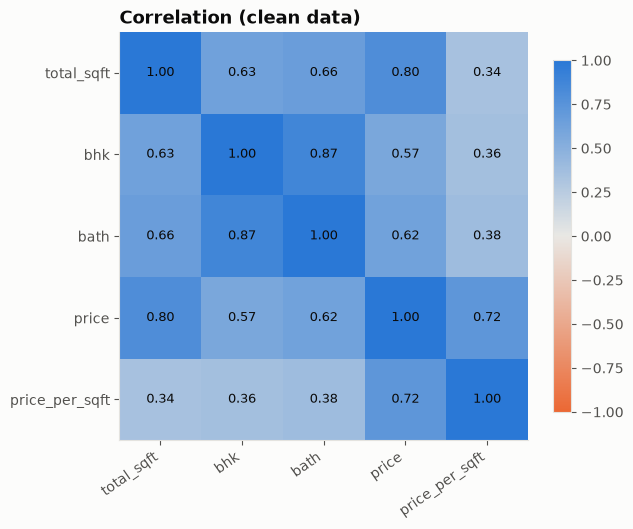

In [10]:
cols = ['total_sqft', 'bhk', 'bath', 'price', 'price_per_sqft']
corr = clean[cols].corr()
cmap = LinearSegmentedColormap.from_list('div', [ORANGE, '#e9e8e4', BLUE])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=35, ha='right'); ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', color='#0b0b0b', fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title('Correlation (clean data)')
plt.tight_layout(); plt.show()

**Takeaways:**
- `total_sqft`, `bhk` and `bath` are all strongly correlated with price **and with each other** — bigger homes have more rooms and bathrooms. Tree models handle this collinearity fine.
- `price_per_sqft` is computed from the target, so it is used **only** for outlier removal and never as a feature (that would leak the answer into the model).

## Summary

- Log-transform the target; prices are heavily skewed.
- Location is the main driver of price per sqft — one-hot encode it, pool rare localities.
- Domain rules (≥300 sqft per bedroom, per-location price-per-sqft bands, BHK price inversions, bathroom count) remove most data-entry noise.
- Next step: `python -m ml.train` compares linear and tree models with 5-fold CV.